# **Import Library**

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
from sklearn.metrics import confusion_matrix, f1_score, accuracy_score, precision_score, recall_score, roc_auc_score, classification_report
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
h
# Pustaka untuk pra-pemrosesan data
from sklearn.preprocessing import MinMaxScaler, LabelEncoder
from sklearn.utils import resample

# Pustaka untuk manipulasi data dan visualisasi
import matplotlib.pyplot as plt
from random import randint
import seaborn as sns
import pandas as pd
import numpy as np

# **Memuat Dataset**

In [ ]:
Data = pd.read_csv("/content/drive/MyDrive/Machine Learning/Project/dataset-stroke.csv")
print("Dataset berhasil dimuat.")

Dataset berhasil dimuat.


# **Pembersihan dan Pra-pemrosesan Data**

In [ ]:
print("\nJumlah Nilai Hilang per Kolom:")
print(Data.isnull().sum().sort_values(ascending=False).head())

# Mengisi nilai yang hilang pada kolom 'bmi' dengan nilai rata-rata (mean)
bmi_mean = round(Data['bmi'].mean(), 1)
Data['bmi'].fillna(bmi_mean, inplace=True)
print(f"\nNilai yang hilang pada 'bmi' telah diisi dengan nilai rata-rata: {bmi_mean}")

bins = [0, 18, 36, 54, 72, 90]
labels = ['0-18', '18-36', '36-54', '54-72', '72-90']
Data['age'] = pd.cut(Data['age'], bins=bins, labels=labels, right=True)
print("\nData setelah kolom 'age' diubah menjadi kategori:")
display(Data.head())


Jumlah Nilai Hilang per Kolom:
bmi             201
id                0
age               0
gender            0
hypertension      0
dtype: int64

Nilai yang hilang pada 'bmi' telah diisi dengan nilai rata-rata: 28.9

Data setelah kolom 'age' diubah menjadi kategori:


/tmp/ipython-input-10-811497365.py:6: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  Data['bmi'].fillna(bmi_mean, inplace=True)


,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,54-72,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,54-72,0,0,Yes,Self-employed,Rural,202.21,28.9,never smoked,1
2,31112,Male,72-90,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,36-54,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,72-90,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


# **Analisis Data**

/tmp/ipython-input-11-926741578.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='stroke', palette=colors[value], data=StrokeAnalysis)


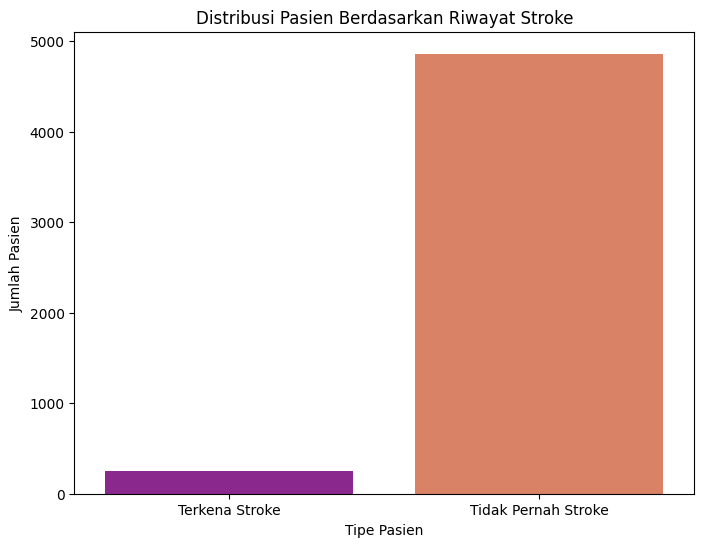

Analisis: Jumlah pasien yang pernah terkena stroke jauh lebih sedikit dibandingkan yang tidak.


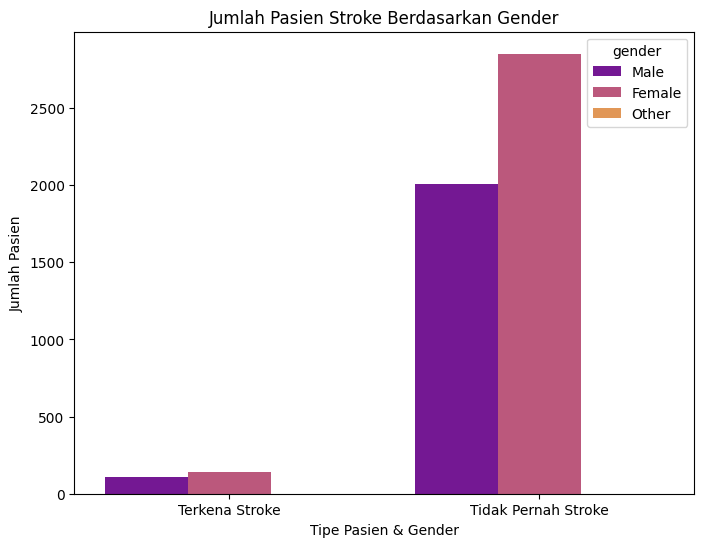

Analisis: Mayoritas pasien dalam dataset ini adalah perempuan.


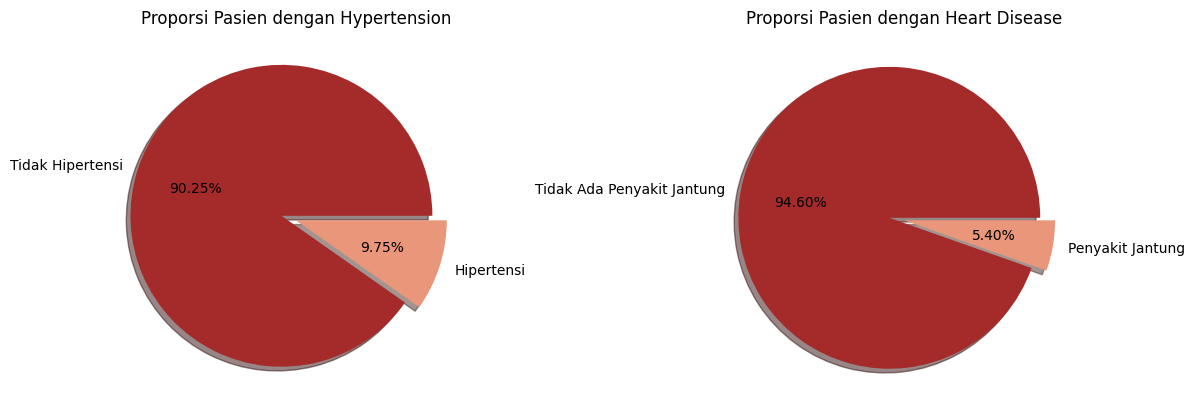

Analisis: Proporsi pasien dengan hipertensi dan penyakit jantung relatif rendah.


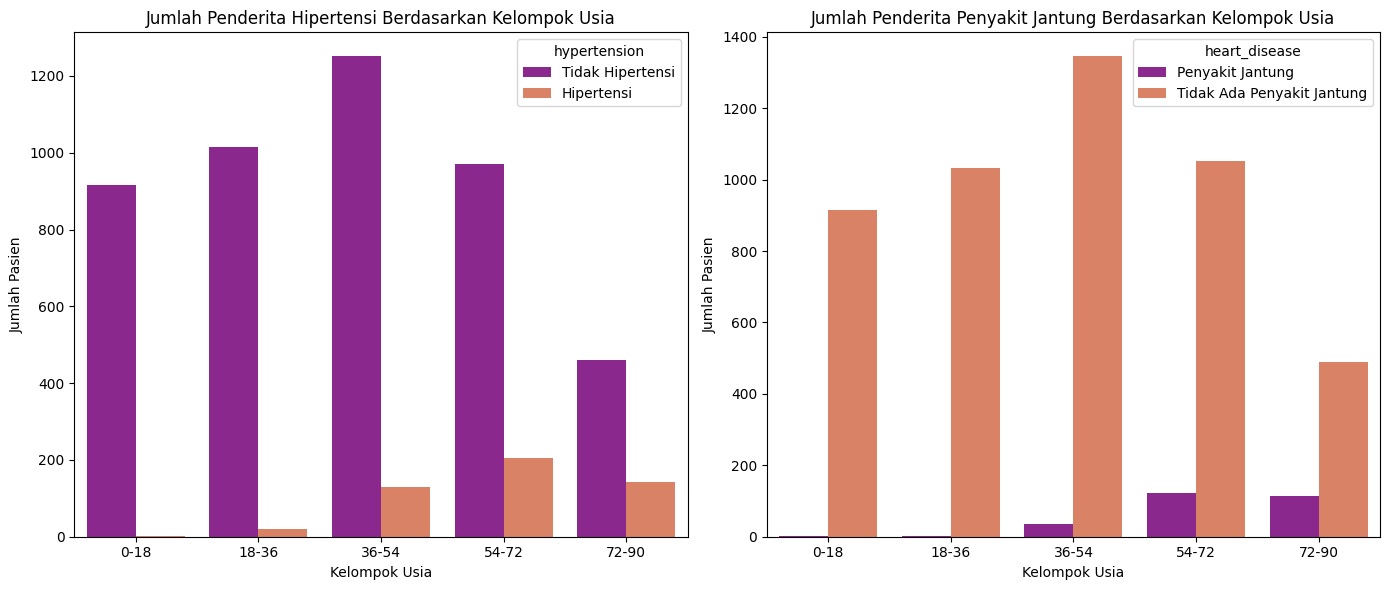

Analisis: Risiko hipertensi dan penyakit jantung meningkat seiring bertambahnya usia.


In [ ]:
StrokeAnalysis = Data.copy()

# Mengubah nilai 0/1 menjadi label yang lebih deskriptif
StrokeAnalysis['hypertension'] = StrokeAnalysis['hypertension'].apply(lambda x: 'Hipertensi' if x == 1 else 'Tidak Hipertensi')
StrokeAnalysis['heart_disease'] = StrokeAnalysis['heart_disease'].apply(lambda x: 'Penyakit Jantung' if x == 1 else 'Tidak Ada Penyakit Jantung')
StrokeAnalysis['stroke'] = StrokeAnalysis['stroke'].apply(lambda x: 'Terkena Stroke' if x == 1 else 'Tidak Pernah Stroke')
StrokeAnalysis['ever_married'] = StrokeAnalysis['ever_married'].apply(lambda x: 'Menikah' if x == 'Yes' else 'Belum Menikah')

# Daftar palet warna untuk visualisasi
colors = ["viridis", "plasma", "inferno", "magma", "cividis"]
value = randint(0, len(colors) - 1)

# --- Visualisasi 1: Distribusi Pasien Stroke ---
plt.figure(figsize=(8, 6))
sns.countplot(x='stroke', palette=colors[value], data=StrokeAnalysis)
plt.title('Distribusi Pasien Berdasarkan Riwayat Stroke')
plt.xlabel("Tipe Pasien")
plt.ylabel("Jumlah Pasien")
plt.show()
print("Analisis: Jumlah pasien yang pernah terkena stroke jauh lebih sedikit dibandingkan yang tidak.")

# --- Visualisasi 2: Stroke Berdasarkan Gender ---
plt.figure(figsize=(8, 6))
sns.countplot(x='stroke', hue='gender', palette=colors[value], data=StrokeAnalysis)
plt.title('Jumlah Pasien Stroke Berdasarkan Gender')
plt.xlabel("Tipe Pasien & Gender")
plt.ylabel("Jumlah Pasien")
plt.show()
print("Analisis: Mayoritas pasien dalam dataset ini adalah perempuan.")

# --- Visualisasi 3: Proporsi Hipertensi dan Penyakit Jantung ---
plt.figure(figsize=(12, 6))
for i, col in enumerate(['hypertension', 'heart_disease'], 1):
    plt.subplot(1, 2, i)
    labels = StrokeAnalysis[col].value_counts().index
    values = StrokeAnalysis[col].value_counts().values
    explode = (0.1, 0)
    plt.pie(values, labels=labels, autopct='%1.2f%%', shadow=True, explode=explode, colors=['brown', 'darksalmon'])
    plt.title(f'Proporsi Pasien dengan {col.replace("_", " ").title()}')
plt.tight_layout()
plt.show()
print("Analisis: Proporsi pasien dengan hipertensi dan penyakit jantung relatif rendah.")

# --- Visualisasi 4: Hubungan Usia dengan Hipertensi dan Penyakit Jantung ---
plt.figure(figsize=(14, 6))
plt.subplot(1, 2, 1)
sns.countplot(x='age', hue='hypertension', palette=colors[value], data=StrokeAnalysis)
plt.title('Jumlah Penderita Hipertensi Berdasarkan Kelompok Usia')
plt.xlabel("Kelompok Usia")
plt.ylabel("Jumlah Pasien")
plt.subplot(1, 2, 2)
sns.countplot(x='age', hue='heart_disease', palette=colors[value], data=StrokeAnalysis)
plt.title('Jumlah Penderita Penyakit Jantung Berdasarkan Kelompok Usia')
plt.xlabel("Kelompok Usia")
plt.ylabel("Jumlah Pasien")
plt.tight_layout()
plt.show()
print("Analisis: Risiko hipertensi dan penyakit jantung meningkat seiring bertambahnya usia.")


# **PEMODELAN DATA**


Distribusi 'avg_glucose_level' dan 'bmi' sebelum dan sesudah penghapusan outlier:


/tmp/ipython-input-12-3849327771.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=Data['avg_glucose_level'], palette=colors[value])
/tmp/ipython-input-12-3849327771.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=Data['avg_glucose_level'], palette=colors[value])


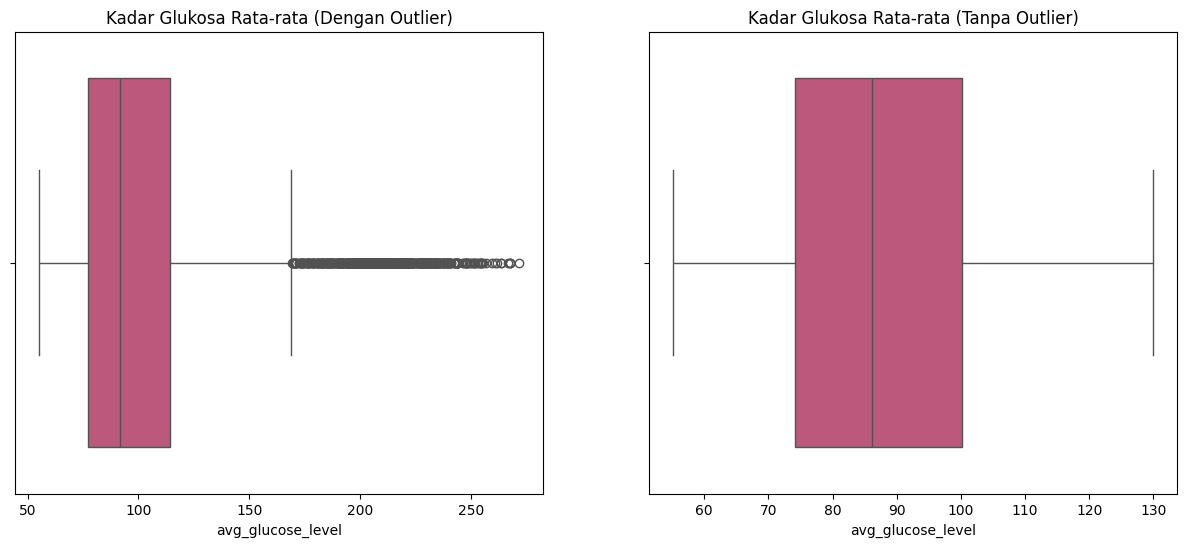

/tmp/ipython-input-12-3849327771.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=Data['bmi'], palette=colors[value])
/tmp/ipython-input-12-3849327771.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=Data['bmi'], palette=colors[value])


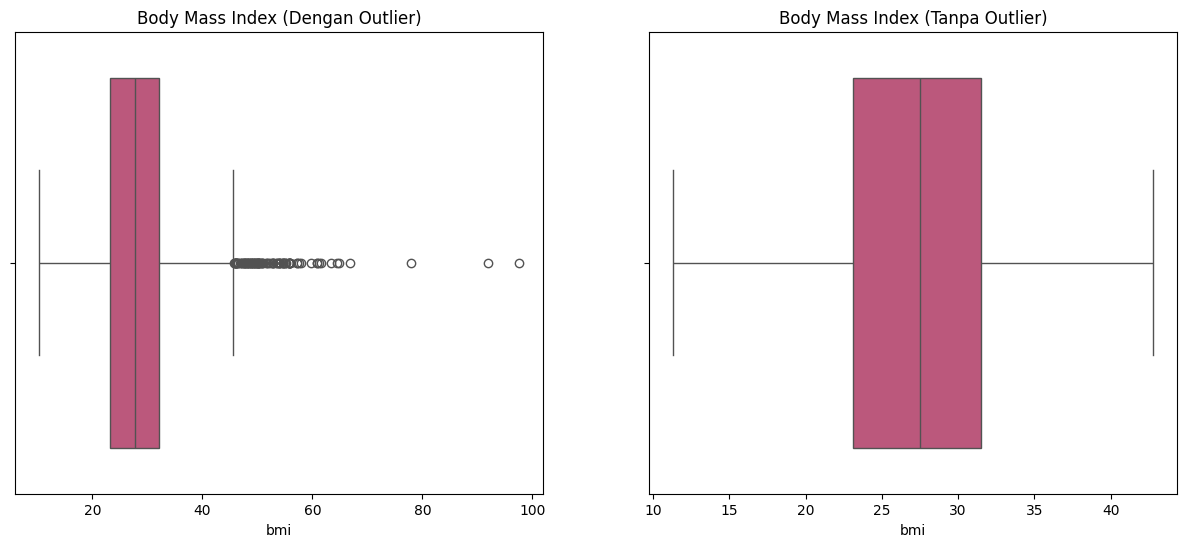


Data setelah encoding:


,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
2,31112,1,4,0,1,1,2,0,105.92,32.5,2,1
6,53882,1,4,1,1,1,2,0,70.09,27.4,2,1
7,10434,0,3,0,0,0,2,1,94.39,22.8,2,1
8,27419,0,3,0,0,1,2,0,76.15,28.9,0,1
9,60491,0,4,0,0,1,2,1,58.57,24.2,0,1


In [ ]:
# Menghapus Outlier
print("\nDistribusi 'avg_glucose_level' dan 'bmi' sebelum dan sesudah penghapusan outlier:")
plt.figure(figsize=(15, 6))
plt.subplot(1, 2, 1)
sns.boxplot(x=Data['avg_glucose_level'], palette=colors[value])
plt.title("Kadar Glukosa Rata-rata (Dengan Outlier)")
Data = Data[Data['avg_glucose_level'] < 130] # Filter outlier
plt.subplot(1, 2, 2)
sns.boxplot(x=Data['avg_glucose_level'], palette=colors[value])
plt.title("Kadar Glukosa Rata-rata (Tanpa Outlier)")
plt.show()

plt.figure(figsize=(15, 6))
plt.subplot(1, 2, 1)
sns.boxplot(x=Data['bmi'], palette=colors[value])
plt.title("Body Mass Index (Dengan Outlier)")
Data = Data[(Data['bmi'] > 10.3) & (Data['bmi'] < 43)] # Filter outlier
plt.subplot(1, 2, 2)
sns.boxplot(x=Data['bmi'], palette=colors[value])
plt.title("Body Mass Index (Tanpa Outlier)")
plt.show()

# Encoding Variabel Kategorikal menjadi Numerik
encoder = LabelEncoder()
columns_to_encode = ['gender', 'age', 'hypertension', 'ever_married', 'work_type', 'Residence_type', 'smoking_status']
for col in columns_to_encode:
    Data[col] = encoder.fit_transform(Data[col])
print("\nData setelah encoding:")
display(Data.head())


# **Penyeimbangan Data**

In [ ]:
print("\n--- Memulai proses penyeimbangan data (500 vs 500) ---")
# Pisahkan data berdasarkan kelas
majority = Data[Data['stroke'] == 0]
minority = Data[Data['stroke'] == 1]

# Downsample kelas mayoritas menjadi 500
downsampled_majority = majority.sample(n=500, random_state=42)

# Upsample kelas minoritas menjadi 500
upsampled_minority = resample(minority,
                              replace=True,          # Mengizinkan duplikasi sampel
                              n_samples=500,         # Target sampel 500
                              random_state=42)       # Seed untuk hasil yang konsisten

# Gabungkan data yang sudah seimbang
StrokeData = pd.concat([downsampled_majority, upsampled_minority])

# Acak data agar tersebar merata
StrokeData = StrokeData.sample(frac=1, random_state=42).reset_index(drop=True)

print(f"\nJumlah total data setelah penyeimbangan: {len(StrokeData)}")
print("Distribusi kelas setelah penyeimbangan:")
print(StrokeData['stroke'].value_counts())


--- Memulai proses penyeimbangan data (500 vs 500) ---

Jumlah total data setelah penyeimbangan: 1000
Distribusi kelas setelah penyeimbangan:
stroke
1    500
0    500
Name: count, dtype: int64


# **Latih Model**



EVALUASI MODEL: Random Forest 


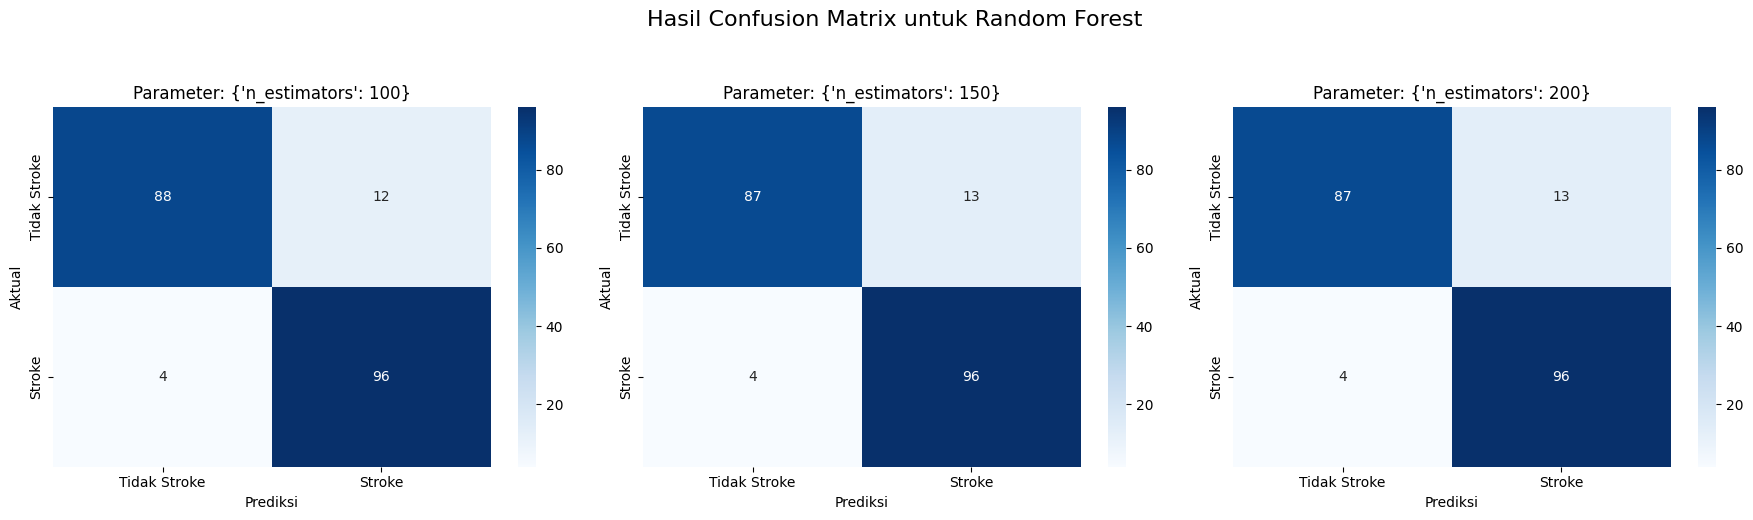

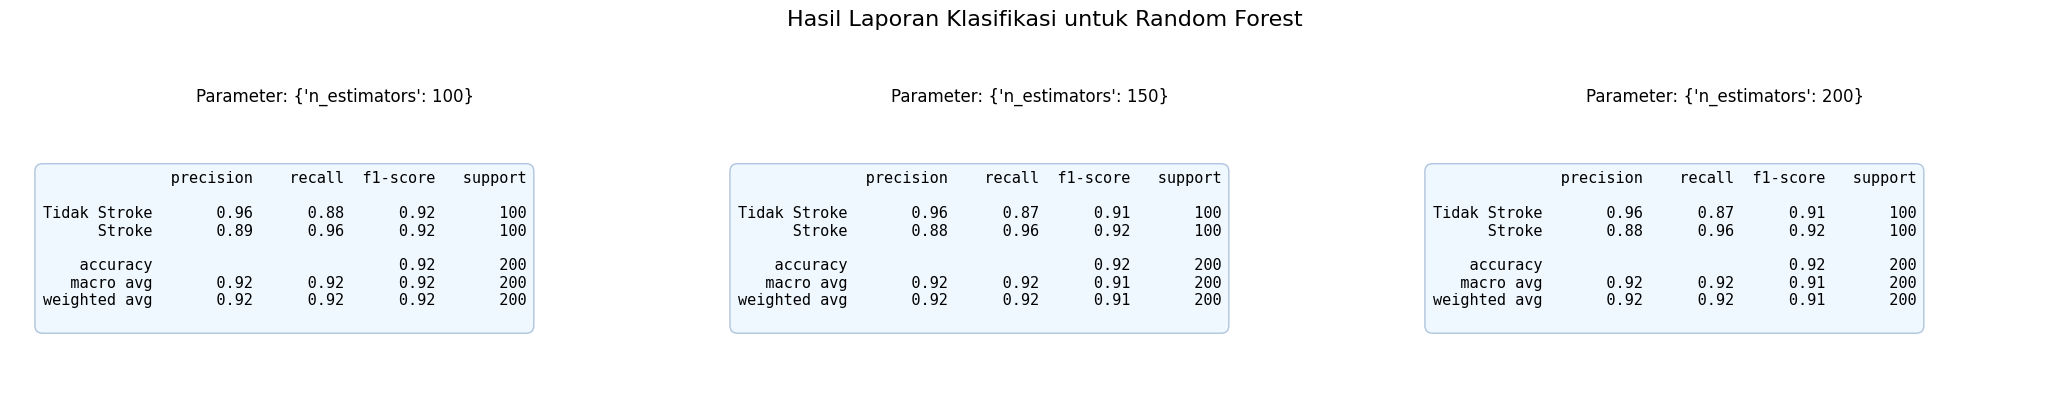



EVALUASI MODEL: Decision Tree 


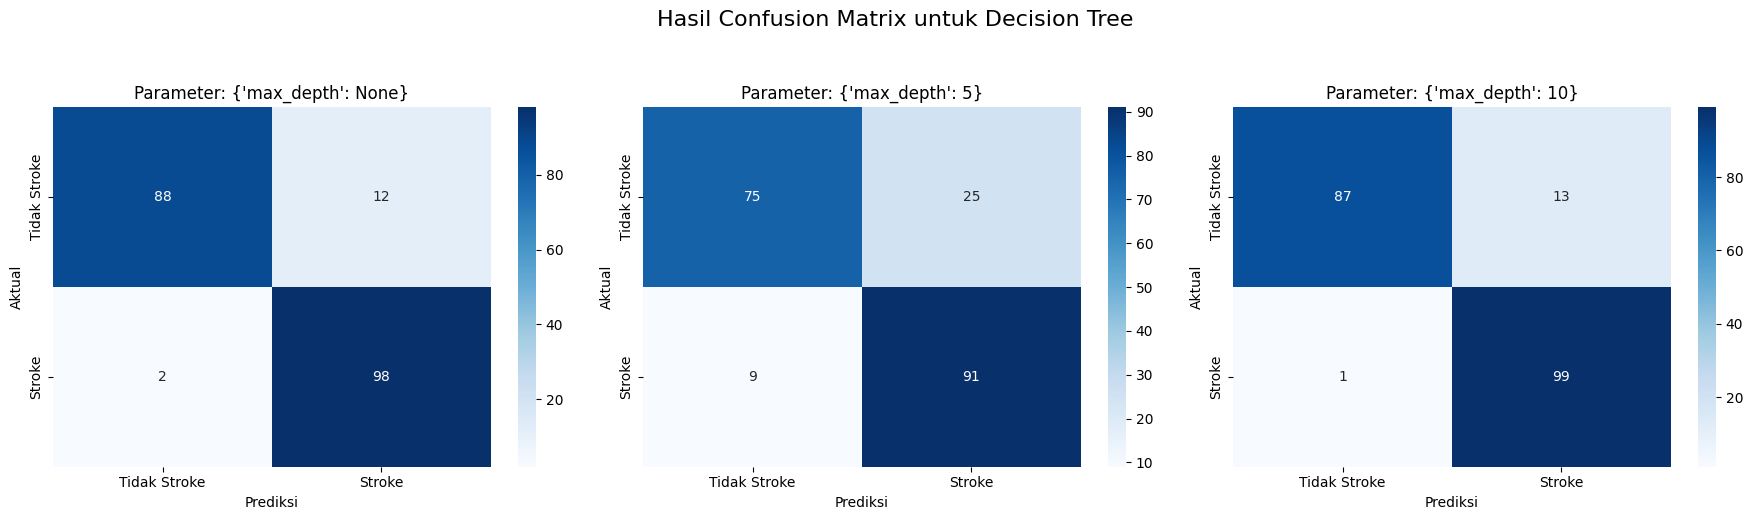

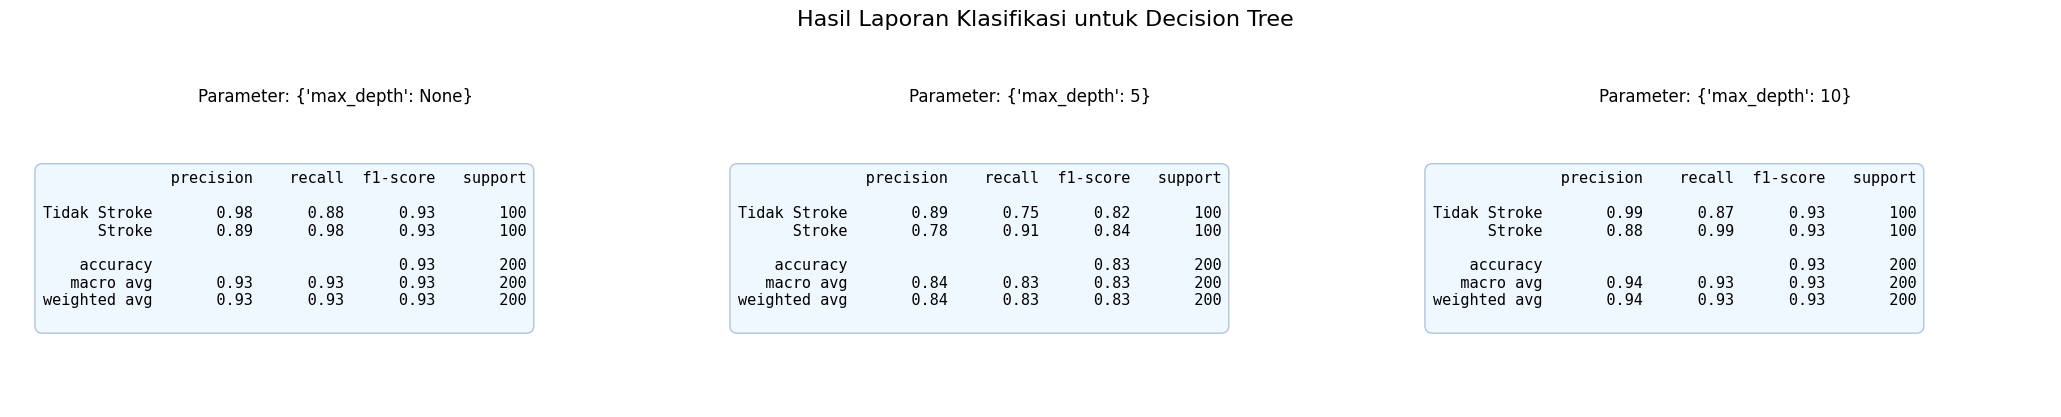



EVALUASI MODEL: Logistic Regression 


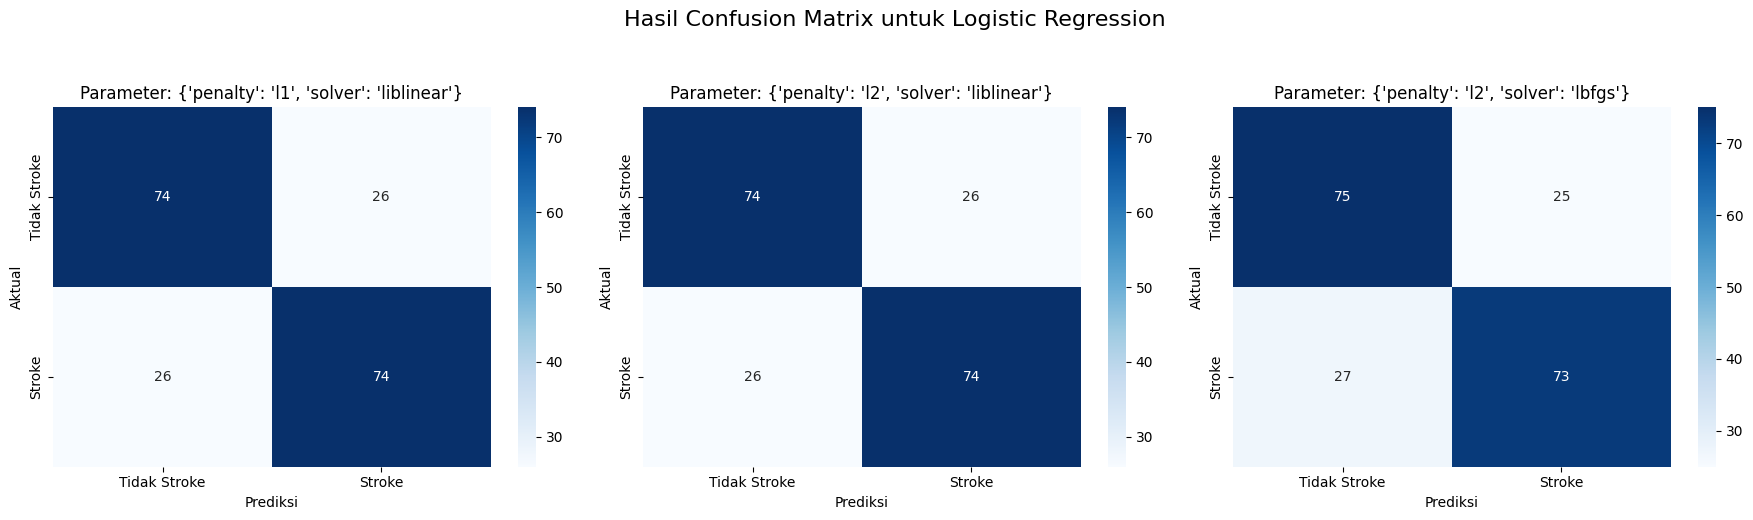

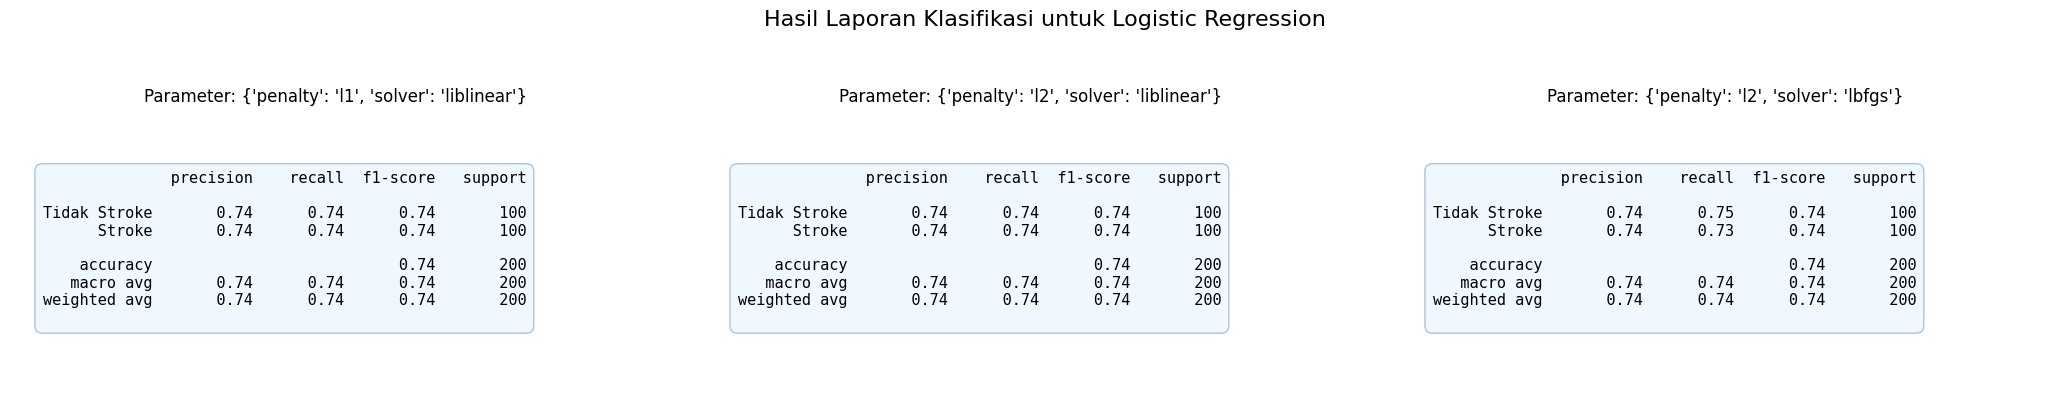



EVALUASI MODEL: K-Nearest Neighbour 


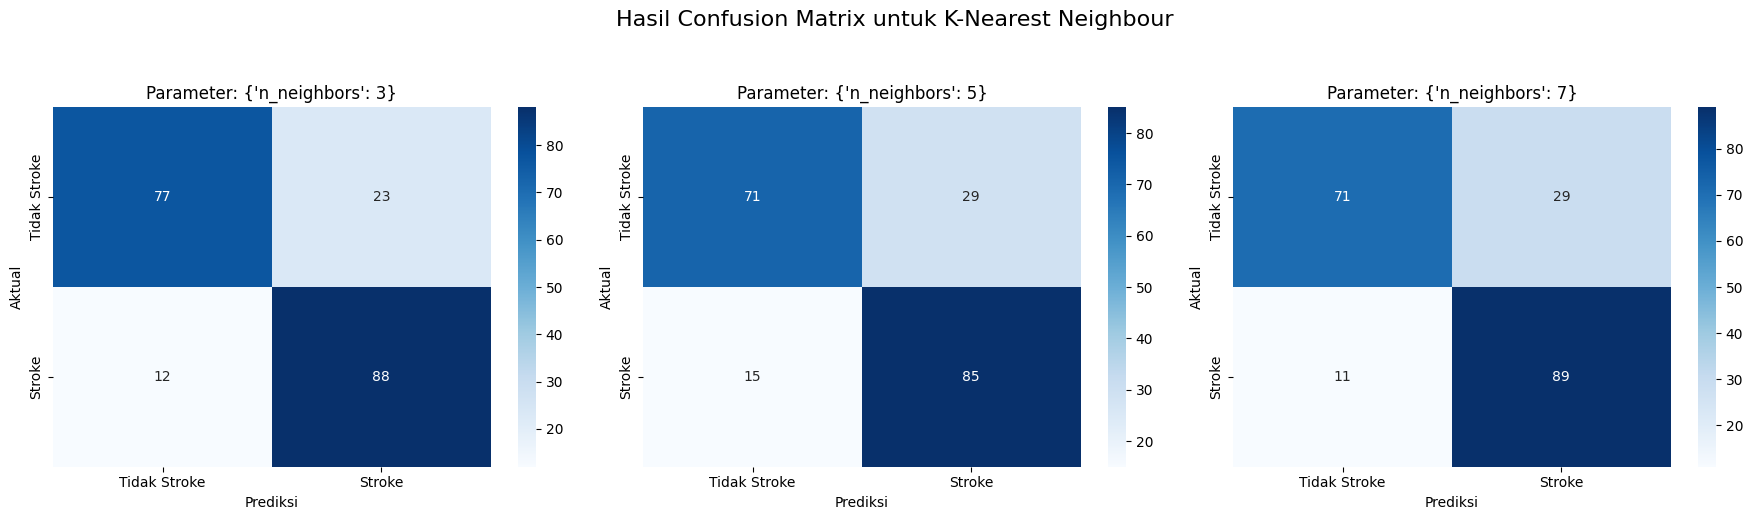

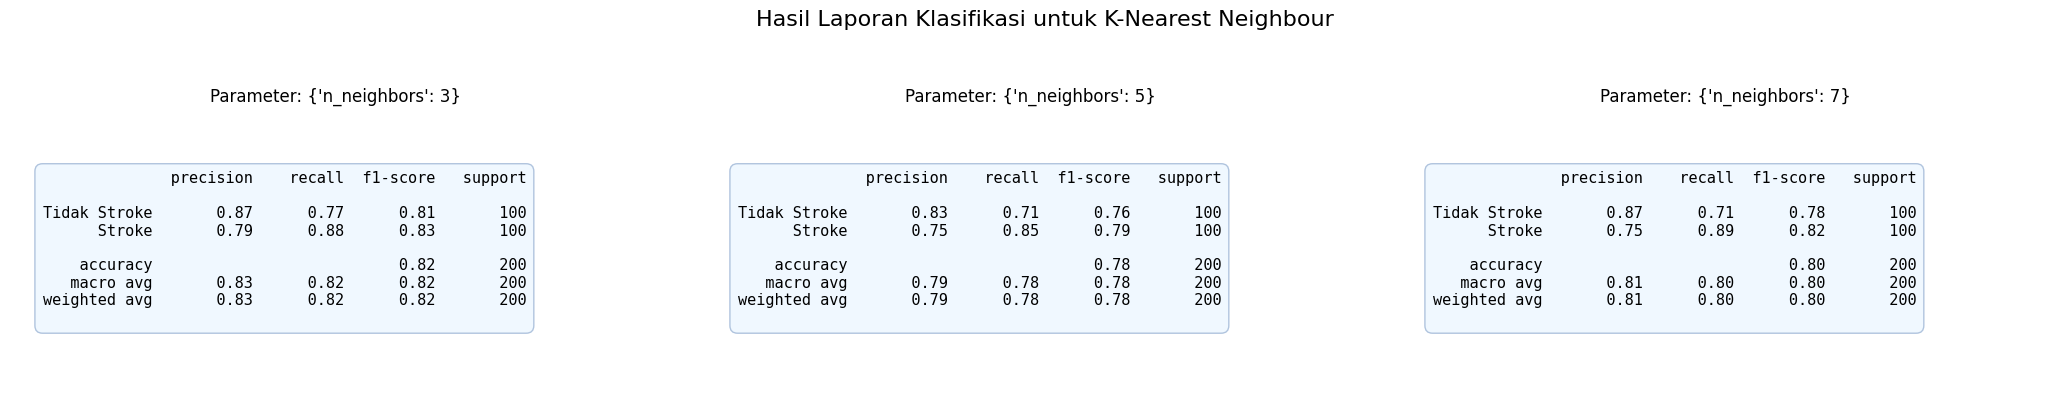



EVALUASI MODEL: Support Vector Classifier 


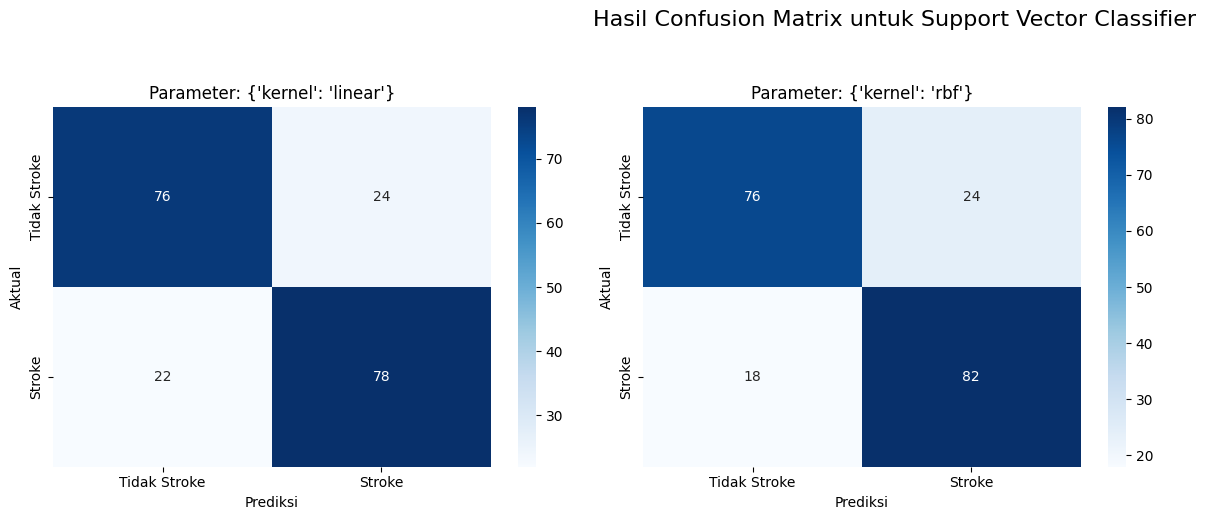

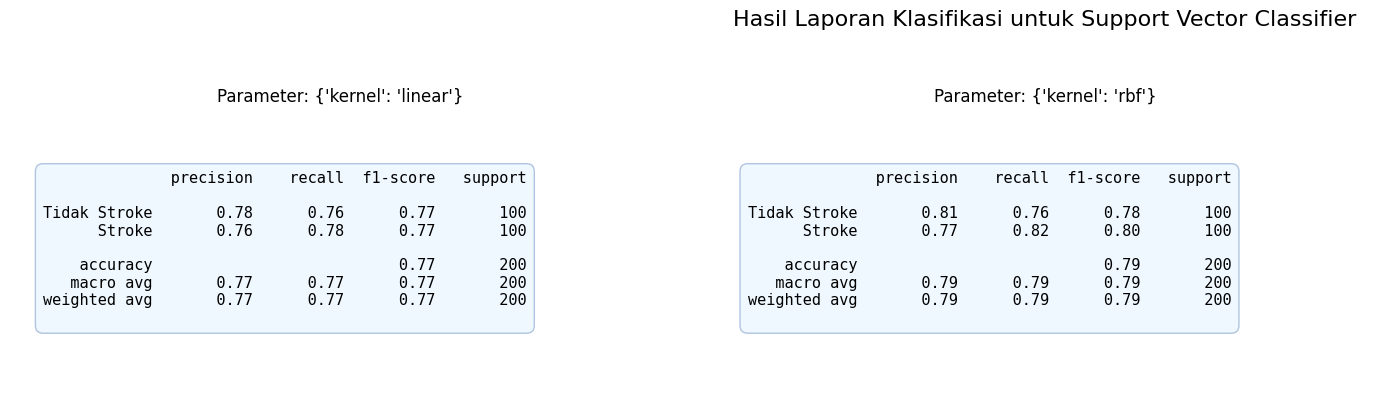

In [ ]:
# Pustaka tambahan untuk iterasi parameter dan matematika
from sklearn.model_selection import ParameterGrid
import math

# Memisahkan fitur (X) dan target (y) dari data seimbang
X = StrokeData.drop(['id', 'stroke'], axis=1)
y = StrokeData['stroke']

# Bagi data menjadi data latih dan uji
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Normalisasi data
scaler = MinMaxScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Daftar algoritma dan hyperparameter yang akan diuji
param_grids = {
    "Random Forest": {
        'n_estimators': [100, 150, 200]
    },
    "Decision Tree": {
        'max_depth': [None, 5, 10]
    },
    "Logistic Regression": [
        {'solver': ['liblinear'], 'penalty': ['l1', 'l2']},
        {'solver': ['lbfgs'], 'penalty': ['l2']}
    ],
    "K-Nearest Neighbour": {
        'n_neighbors': [3, 5, 7]
    },
    "Support Vector Classifier": {
        'kernel': ['linear', 'rbf']
    }
}

# Daftar model dasar untuk diiterasi
base_models = {
    "Random Forest": RandomForestClassifier(random_state=42),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "K-Nearest Neighbour": KNeighborsClassifier(),
    "Support Vector Classifier": SVC(random_state=42)
}

# List untuk menyimpan hasil terbaik dari setiap model untuk perbandingan akhir
final_comparison_list = []

# Loop untuk melatih dan mengevaluasi setiap kombinasi hyperparameter
for name, model_params in param_grids.items():
    print(f"\n\nEVALUASI MODEL: {name} ")

    grid = ParameterGrid(model_params)
    results_for_model = []

    best_f1_for_model = -1
    best_result_for_model = {}

    # Kumpulkan hasil untuk setiap kombinasi parameter terlebih dahulu
    for params in grid:
        model = base_models[name]
        model.set_params(**params)
        model.fit(X_train, y_train)
        prediction = model.predict(X_test)

        current_f1 = f1_score(y_test, prediction) # Gunakan f1 score kelas positif (stroke=1)

        result_data = {
            'params': params,
            'cm': confusion_matrix(y_test, prediction),
            'report': classification_report(y_test, prediction, target_names=['Tidak Stroke', 'Stroke']),
            'accuracy': accuracy_score(y_test, prediction),
            'precision': precision_score(y_test, prediction),
            'recall': recall_score(y_test, prediction),
            'f1_score': current_f1
        }
        results_for_model.append(result_data)

        # Lacak hasil terbaik untuk model ini
        if current_f1 > best_f1_for_model:
            best_f1_for_model = current_f1
            best_result_for_model = result_data

    # --- Tampilkan Confusion Matrix dalam Grid ---
    num_params = len(results_for_model)
    ncols = 3
    nrows = math.ceil(num_params / ncols)

    fig_cm, axes_cm = plt.subplots(nrows, ncols, figsize=(ncols * 6, nrows * 5))
    axes_cm = np.array(axes_cm).flatten()

    fig_cm.suptitle(f'Hasil Confusion Matrix untuk {name}', fontsize=16, y=1.03)

    for i, result in enumerate(results_for_model):
        sns.heatmap(result['cm'], ax=axes_cm[i], annot=True, fmt='d', cmap='Blues',
                    xticklabels=['Tidak Stroke', 'Stroke'],
                    yticklabels=['Tidak Stroke', 'Stroke'])
        axes_cm[i].set_title(f"Parameter: {result['params']}", fontsize=12)
        axes_cm[i].set_xlabel('Prediksi')
        axes_cm[i].set_ylabel('Aktual')

    for i in range(num_params, len(axes_cm)):
        axes_cm[i].set_visible(False)

    plt.tight_layout(rect=[0, 0, 1, 0.98])
    plt.show()

    # --- Tampilkan Laporan Klasifikasi dalam Grid ---
    fig_report, axes_report = plt.subplots(nrows, ncols, figsize=(ncols * 7, nrows * 4))
    axes_report = np.array(axes_report).flatten()

    fig_report.suptitle(f'Hasil Laporan Klasifikasi untuk {name}', fontsize=16, y=1.03)

    for i, result in enumerate(results_for_model):
        report_str = result['report']
        params_str = str(result['params'])

        ax = axes_report[i]
        ax.axis('off')
        ax.set_title(f"Parameter: {params_str}", fontsize=12, pad=20)

        ax.text(0.05, 0.85, report_str, transform=ax.transAxes,
                ha='left', va='top', fontsize=11, family='monospace',
                bbox=dict(boxstyle='round,pad=0.5', fc='aliceblue', ec='lightsteelblue', lw=1))

    for i in range(num_params, len(axes_report)):
        axes_report[i].set_visible(False)

    plt.tight_layout(rect=[0, 0, 1, 0.96])
    plt.show()

    # Simpan hasil terbaik dari model ini untuk perbandingan akhir
    final_comparison_list.append({
        'Algoritma': name,
        'Akurasi': best_result_for_model['accuracy'],
        'Precision': best_result_for_model['precision'],
        'Recall': best_result_for_model['recall'],
        'F1-Score': best_result_for_model['f1_score'],
        'Hyperparameter Terbaik': best_result_for_model['params']
    })



# **Perbandingan Model**

In [ ]:
# Buat DataFrame dari hasil terbaik yang disimpan
comparison_df = pd.DataFrame(final_comparison_list)

# Urutkan DataFrame berdasarkan F1-Score
comparison_df_sorted = comparison_df.sort_values(by='F1-Score', ascending=False).reset_index(drop=True)

# Tampilkan DataFrame dengan format yang lebih baik
pd.set_option('display.max_colwidth', None)
display(comparison_df_sorted)

,Algoritma,Akurasi,Precision,Recall,F1-Score,Hyperparameter Terbaik
0,Decision Tree,0.930,0.883929,0.99,0.933962,{'max_depth': 10}
1,Random Forest,0.920,0.888889,0.96,0.923077,{'n_estimators': 100}
2,K-Nearest Neighbour,0.825,0.792793,0.88,0.834123,{'n_neighbors': 3}
3,Support Vector Classifier,0.790,0.773585,0.82,0.796117,{'kernel': 'rbf'}
4,Logistic Regression,0.740,0.740000,0.74,0.740000,"{'penalty': 'l1', 'solver': 'liblinear'}"
